Since we completed 1CCCV charge protocol now let's charge with 1CPCV.
First, we need to define what is the value of 1P.
1P = Vnominal * 1C
I could not find any Vonimal parameter in the Chen2020. So I will take Vnominal as 3.6V this specific cell.

In [124]:
import pybamm
import matplotlib.pyplot as plt

In [125]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0); # Set initial state of charge to 0%

In [126]:
Vnom = 3.6 # Nominal voltage of the cell
Qnom = parameter_values["Nominal cell capacity [A.h]"]
P_1P = Vnom * Qnom # Nominal power of the cell
print("Nominal power of the cell: ", P_1P, "W")

Nominal power of the cell:  18.0 W


In [127]:
CPCV_Charging = pybamm.Experiment([
    f"Charge at {P_1P} W until 4.2 V",
     "Hold at 4.2 V until C/20"])


In [128]:
model = pybamm.lithium_ion.DFN() # Create a DFN model
sim = pybamm.Simulation(model, experiment=CPCV_Charging,parameter_values=parameter_values)
sim.solve() # Solve the simulation

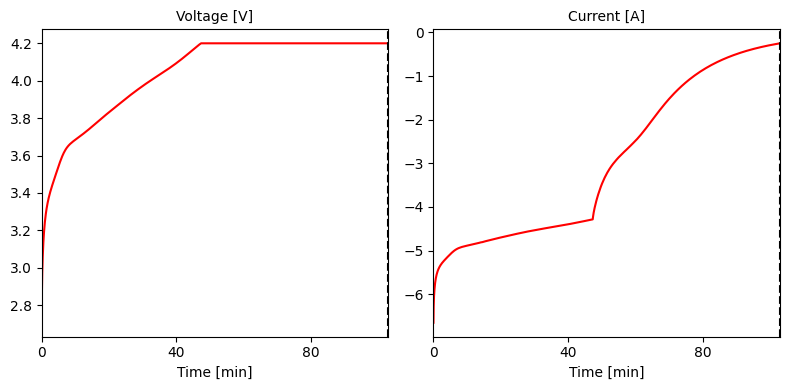

In [129]:
qp = pybamm.QuickPlot(sim.solution,output_variables=["Voltage [V]", "Current [A]",], time_unit="minutes")
qp.plot(qp.max_t) # Plot the voltage and current over time for the entire experiment

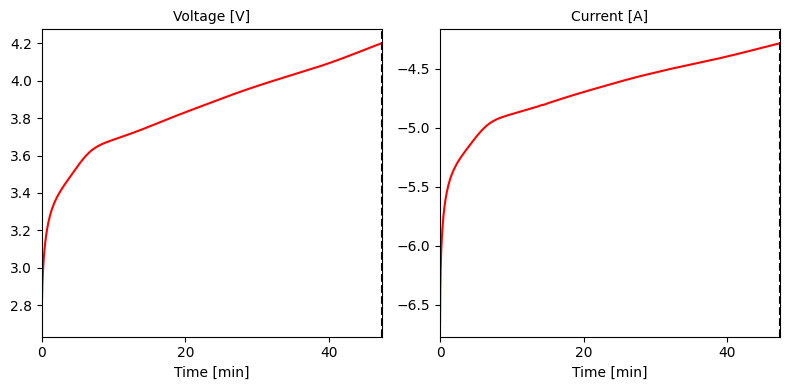

In [130]:
CP_Phase = sim.solution.cycles[0] # Get the constant power phase of the charging cycle with 18W
qp_CP = pybamm.QuickPlot(CP_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp_CP.plot(qp_CP.max_t) # Plot the voltage and current over time for the constant power

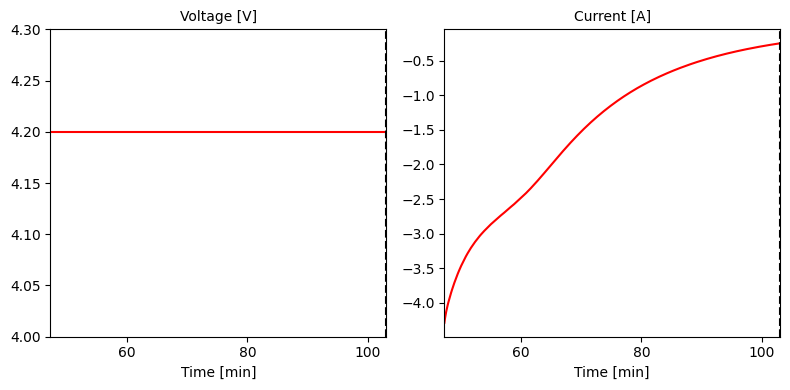

In [131]:
CV_Phase = sim.solution.cycles[1] # Get the constant voltage phase of the charging cycle with 4.2V
qp_CV = pybamm.QuickPlot(CV_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes", variable_limits={"Voltage [V]": (4.0, 4.3)})
qp_CV.plot(qp_CV.max_t) # Plot the voltage and current over time for the constant voltage with 4.2V